# 🧠 Semana 9 · Fundamentos de Deep Learning
## **AulaSense: una red neuronal que aprende a reconocer salas de estudio cómodas**

**Curso:** Inteligencia Artificial · UNMSM · Ingeniería de Sistemas  
**Tema:** Redes neuronales artificiales (ANN), propagación, retropropagación y convergencia del error.

### ¿Qué vas a observar?
1. Creamos datos **sintéticos** de temperatura y ruido (no representan mediciones reales).
2. Entrenamos una red neuronal con **dos capas ocultas** para reconocer un patrón **no lineal**.
3. Vemos cómo disminuye el **error** y comparamos la ANN con un modelo clásico.
4. Probamos casos nuevos con controles interactivos.

> **Pregunta guía:** ¿Puede una red neuronal aprender qué combinaciones de temperatura y ruido cumplen una regla sin que se programe esa regla directamente en su arquitectura?

⏱️ **Duración orientativa:** pocos minutos en Google Colab, con CPU. No necesitas archivos externos ni GPU.

### 1 · Crear un pequeño conjunto de datos

Simulamos 900 situaciones de una sala de estudio. Definimos una **regla didáctica**, solo para poder evaluar si el modelo aprende:

- **Adecuada (1):** temperatura de **20 a 26 °C** y ruido de **58 dB o menos**.
- **Revisar (0):** cualquiera de las demás combinaciones.

Los umbrales son inventados para esta demostración: **no son normas técnicas de confort**. El modelo no verá la regla, solo ejemplos etiquetados.

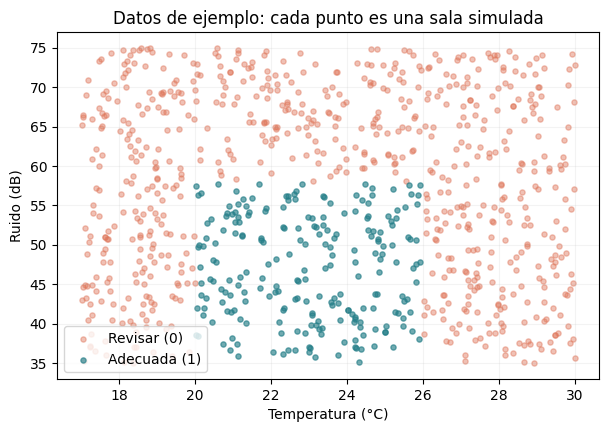

Muestras: 900 | Adecuadas: 227 | Para revisar: 673


In [1]:
# Keras 3 con PyTorch como motor: funciona en Google Colab sin descargar datasets.
import os
os.environ["KERAS_BACKEND"] = "torch"   # antes de importar keras

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

rng = np.random.default_rng(42)
keras.utils.set_random_seed(42)

n = 900
temperatura = rng.uniform(17, 30, n)  # °C
ruido = rng.uniform(35, 75, n)        # dB
X = np.column_stack([temperatura, ruido])
y = ((temperatura >= 20) & (temperatura <= 26) & (ruido <= 58)).astype(int)

plt.figure(figsize=(7, 4.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=14, alpha=.45, label="Revisar (0)", c="#df775b")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=14, alpha=.65, label="Adecuada (1)", c="#247e88")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Ruido (dB)")
plt.title("Datos de ejemplo: cada punto es una sala simulada")
plt.legend()
plt.grid(alpha=.15)
plt.show()
print(f"Muestras: {len(y)} | Adecuadas: {sum(y==1)} | Para revisar: {sum(y==0)}")

### 2 · Preparar los datos y construir la ANN

La red recibe **2 entradas** y pasa la información por dos capas ocultas de **24 y 12 neuronas (ReLU)**; al final, una neurona **sigmoide** devuelve un puntaje entre 0 y 1.

`Temperatura + Ruido  →  24 ReLU  →  12 ReLU  →  1 Sigmoide`

**Pesos y sesgos** se ajustan durante el entrenamiento. **Adam** usa los gradientes obtenidos por **retropropagación** para minimizar la *entropía cruzada binaria*.

Separamos primero entrenamiento (80 %) y prueba (20 %), y **normalizamos usando solo el entrenamiento** para no filtrar información de la prueba.

In [2]:
# Datos de prueba: quedan aparte y no intervienen en el entrenamiento.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

red = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(24, activation="relu"),
    layers.Dense(12, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="AulaSense_ANN")
red.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.008),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
red.summary()

Model: "AulaSense_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 24)             │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

### 3 · Entrenar y comparar con ML clásico

Una **época** significa que la red vio todo el entrenamiento una vez. En cada época: predice → calcula el error → obtiene gradientes → actualiza pesos.

Reservamos parte del entrenamiento para **validación**. `EarlyStopping` detiene el ajuste cuando ya no mejora esa pérdida, y recupera los mejores pesos. Como referencia clásica entrenamos una **regresión logística** sobre los mismos datos.

In [3]:
historial = red.fit(
    X_train, y_train,
    validation_split=0.20,
    epochs=90, batch_size=32, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True
    )]
)

clasico = LogisticRegression(max_iter=400).fit(X_train, y_train)
pred_clasico = clasico.predict(X_test)
pred_ann = (red.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)

print(f"Épocas entrenadas: {len(historial.history['loss'])}")
print("MODELO               EXACTITUD    F1 de 'Adecuada'")
print(f"Regresión logística    {accuracy_score(y_test, pred_clasico):7.1%}       {f1_score(y_test, pred_clasico):7.1%}")
print(f"ANN AulaSense          {accuracy_score(y_test, pred_ann):7.1%}       {f1_score(y_test, pred_ann):7.1%}")

Épocas entrenadas: 43
MODELO               EXACTITUD    F1 de 'Adecuada'
Regresión logística      72.8%         34.7%
ANN AulaSense            96.7%         93.8%


### 4 · Lo más importante: ver cómo aprende

- **Gráfica izquierda:** la pérdida (*loss*) de entrenamiento y validación. Al bajar, indica que la red mejora su ajuste.
- **Gráfica central:** mapa de decisiones que la ANN aprendió. El área verde representa donde predice “Adecuada”.
- **Gráfica derecha:** matriz de confusión con ejemplos nunca usados para entrenar.

**Ojo:** una pérdida baja **no demuestra** que funcione con aulas reales; solo evalúa este experimento sintético.

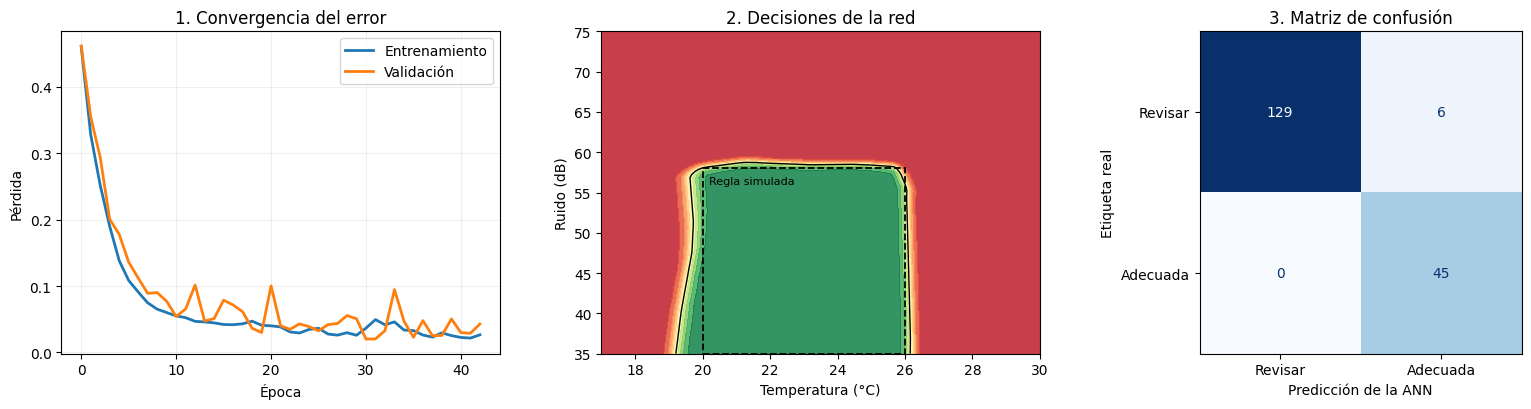

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1) Convergencia: descenso del error durante el aprendizaje.
axes[0].plot(historial.history["loss"], label="Entrenamiento", lw=2)
axes[0].plot(historial.history["val_loss"], label="Validación", lw=2)
axes[0].set(title="1. Convergencia del error", xlabel="Época", ylabel="Pérdida")
axes[0].legend()
axes[0].grid(alpha=.20)

# 2) Zona que la red aprendió a reconocer, no programada en sus capas.
t_vals = np.linspace(17, 30, 100)
r_vals = np.linspace(35, 75, 100)
T, R = np.meshgrid(t_vals, r_vals)
mallado = np.column_stack([T.ravel(), R.ravel()])
Z = scaler.transform(mallado).astype("float32")
mapa = red.predict(Z, verbose=0).reshape(T.shape)
axes[1].contourf(T, R, mapa, levels=np.linspace(0, 1, 11), cmap="RdYlGn", alpha=.83)
axes[1].contour(T, R, mapa, levels=[.5], colors="black", linewidths=1)
from matplotlib.patches import Rectangle
axes[1].add_patch(Rectangle((20, 35), 6, 23, fill=False, ec="black", ls="--", lw=1.3))
axes[1].text(20.2, 56.0, "Regla simulada", fontsize=8)
axes[1].set(title="2. Decisiones de la red", xlabel="Temperatura (°C)", ylabel="Ruido (dB)")

# 3) Exactitud por clase en el conjunto de prueba.
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_ann, display_labels=["Revisar", "Adecuada"],
    ax=axes[2], cmap="Blues", colorbar=False
)
axes[2].set_title("3. Matriz de confusión")
axes[2].set_xlabel("Predicción de la ANN")
axes[2].set_ylabel("Etiqueta real")
plt.tight_layout()
plt.show()

### 5 · Demostración: ¿qué predice en una sala nueva?

Cambia `temp` y `db` y vuelve a ejecutar esta celda. El modelo predice a partir de **valores no usados directamente para crear su respuesta**; no ejecuta la regla dentro de la función `predecir`.

Un resultado cercano a **1** significa que la ANN ve esa combinación como adecuada **según los patrones sintéticos aprendidos**.

In [5]:
def predecir(temp, db):
    entrada = scaler.transform([[temp, db]]).astype("float32")
    puntaje = float(red.predict(entrada, verbose=0)[0, 0])
    decision = "ADECUADA" if puntaje >= 0.5 else "REVISAR"
    return puntaje, decision

# Prueba estos valores o elige otros:
temp, db = 23, 45
puntaje, decision = predecir(temp, db)
print(f"Sala simulada: {temp} °C y {db} dB")
print(f"Puntaje de la ANN: {puntaje:.3f}")
print(f"Predicción: {decision}")

# Tres casos contrastantes para mostrar en la exposición.
for a, b in [(23, 45), (28, 50), (23, 70)]:
    print(f"  {a} °C / {b} dB → {predecir(a, b)[1]}")

Sala simulada: 23 °C y 45 dB
Puntaje de la ANN: 1.000
Predicción: ADECUADA
  23 °C / 45 dB → ADECUADA
  28 °C / 50 dB → REVISAR
  23 °C / 70 dB → REVISAR


#### Extra visual (opcional): mueve los controles en Google Colab

Los deslizadores permiten variar las entradas y observar la predicción sin reentrenar. Si los controles no aparecen en tu entorno, **la celda anterior funciona igualmente**.

In [6]:
try:
    from ipywidgets import interact, IntSlider
except ImportError:
    print("Controles no instalados en este entorno. Usa la celda anterior para cambiar valores.")
else:
    @interact(
        temperatura=IntSlider(value=23, min=17, max=30, description="°C", continuous_update=False),
        ruido=IntSlider(value=45, min=35, max=75, description="dB", continuous_update=False)
    )
    def explorar(temperatura, ruido):
        valor, resultado = predecir(temperatura, ruido)
        print(f"Puntaje: {valor:.3f}  |  Predicción: {resultado}")

Controles no instalados en este entorno. Usa la celda anterior para cambiar valores.


### 6 · Conclusiones para la exposición

**¿Qué se comprobó aquí?**

1. La ANN transforma dos entradas a través de **capas ocultas** con funciones **ReLU**.
2. Los pesos cambian gracias a **retropropagación + Adam** y la **pérdida** suele descender hasta estabilizarse.
3. Una frontera de decisión con forma de zona requiere una relación **no lineal**: una red con capas ocultas puede representarla, mientras que una regresión logística simple tiene una frontera lineal.
4. Una predicción se obtiene usando la red **ya entrenada**, sin repetir el entrenamiento.

**Limitación esencial:** los datos y umbrales fueron inventados para aprender el concepto. Antes de usarlo en ambientes reales, habría que recopilar datos, elegir criterios de confort fundamentados y validar el modelo con usuarios y salas diferentes.

**Para tu diapositiva 14:** coloca una captura de la gráfica de convergencia y el mapa de decisiones, junto a la frase: *«Una red neuronal aprende una relación no lineal y reduce el error mediante retropropagación»*.

---
**Lectura de respaldo:** Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. https://www.deeplearningbook.org/  
Documentación: [Keras — modelos secuenciales](https://keras.io/guides/sequential_model/).